# COMP6008 Smart Irrigation RL — TD3 Experiment Notebook

**Group member:** Arnav Dangmali  
**Location:** Kyabram, Victoria  
**Agent:** Twin Delayed Deep Deterministic Policy Gradient (TD3)  
**Status:** TD3 implementation and implementation checks complete.


## 3. Setup

Run the installation cell once per Colab session. The final run should record the resolved package versions and hardware below.


In [98]:
%pip install -q "gymnasium>=1.0,<2" "numpy>=1.22" "torch>=2.0" "pandas>=2.0" "matplotlib>=3.7"


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [99]:
from __future__ import annotations

import hashlib
import json
import platform
import random
import time
import warnings
from collections import deque
from dataclasses import asdict, dataclass, replace
from datetime import date, timedelta
from itertools import product
from pathlib import Path
from typing import Any
from zipfile import ZipFile

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env

RUNTIME = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "gymnasium": gym.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "torch": torch.__version__,
    "device": "cuda" if torch.cuda.is_available() else "cpu",
}
RUNTIME


{'python': '3.12.6',
 'platform': 'macOS-27.0.1-arm64-arm-64bit',
 'gymnasium': '1.4.0',
 'numpy': '2.5.4',
 'pandas': '3.0.6',
 'torch': '2.14.1',
 'device': 'cpu'}

## 4. Data, provenance and scope

The required archive is [`data/Irrigation_Data_Audit.zip`](../data/Irrigation_Data_Audit.zip).

In [100]:
DATA_CANDIDATES = [
    Path("../data/Irrigation_Data_Audit.zip"),  # when launched from notebooks/
    Path("data/Irrigation_Data_Audit.zip"),    # when working directory is repository root
    Path("Irrigation_Data_Audit.zip"),
    Path("/content/Irrigation_Data_Audit.zip"),
    Path("../irrigation_audit/kyabram_080091_daily.json"),
    Path("irrigation_audit/kyabram_080091_daily.json"),
]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Upload Irrigation_Data_Audit.zip and rerun this cell. "
        "The expected Colab path is /content/Irrigation_Data_Audit.zip."
    )

DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print("Using:", DATA_PATH.resolve())
print("SHA-256:", DATA_SHA256)

# Resolve outputs consistently from repository root, notebooks/, or standalone Colab.
PROJECT_ROOT = next((p.resolve() for p in (Path.cwd(), Path.cwd().parent)
                     if (p / "notebooks").is_dir()), Path.cwd())
OUTPUT_ROOT = PROJECT_ROOT / "outputs"
AGENT_OUTPUT_DIRS = {name: OUTPUT_ROOT / name for name in ("ddpg", "td3", "sac")}

def agent_output_dir(agent_name):
    if agent_name not in AGENT_OUTPUT_DIRS:
        raise ValueError("Choose ddpg, td3, or sac")
    directory = AGENT_OUTPUT_DIRS[agent_name]
    directory.mkdir(parents=True, exist_ok=True)
    return directory


Using: /Users/arnavdangmali/MainFolder/University/Curtin/Sem2/COMP6008/comp6008-smart-irrigation-rl/data/Irrigation_Data_Audit.zip
SHA-256: ce6d02d87ea7cb980f61f78bdd288d6ad035744042dae1eb3e43f0facaa54e08


## 5. Frozen shared settings and declared experimental plans

These settings must be identical across DDPG, TD3 and SAC. Agent-specific selected values remain `None` until validation-only tuning is complete. Test seasons must not influence a setting, checkpoint or reward choice.


In [101]:
TRAIN_YEARS = tuple(range(2005, 2017))
VALIDATION_YEARS = tuple(range(2017, 2021))
TEST_YEARS = tuple(range(2021, 2025))
SEASON_SPLITS = {
    "train": TRAIN_YEARS,
    "validation": VALIDATION_YEARS,
    "test": TEST_YEARS,
    "all": TRAIN_YEARS + VALIDATION_YEARS + TEST_YEARS,
}


@dataclass(frozen=True)
class EnvironmentConfig:
    capacity_mm: float = 111.33333333333334
    initial_storage_fraction: float = 0.80
    max_irrigation_mm: float = 20.0
    irrigation_efficiency: float = 0.85
    season_length_days: int = 150
    planting_month: int = 11
    planting_day: int = 1
    planting_day_offset: int = 0
    kc_multiplier: float = 1.0
    irrigation_weight: float = 1.0
    shortage_weight: float = 10.0
    drainage_weight: float = 1.0
    rainfall_scale_mm: float = 20.0
    eto_scale_mm: float = 10.0
    history_days: int = 7

    def __post_init__(self):
        if self.capacity_mm <= 0 or self.max_irrigation_mm <= 0:
            raise ValueError("Storage capacity and irrigation limit must be positive")
        if not 0 < self.initial_storage_fraction <= 1:
            raise ValueError("Initial storage fraction must be in (0, 1]")
        if not 0 < self.irrigation_efficiency <= 1:
            raise ValueError("Irrigation efficiency must be in (0, 1]")
        if self.season_length_days != 150 or self.history_days != 7:
            raise ValueError("The fixed experiment uses 150 days and seven history days")
        if not 0 < self.kc_multiplier <= 1.1:
            raise ValueError("Kc multiplier must be in (0, 1.1]")
        if min(self.irrigation_weight, self.shortage_weight, self.drainage_weight) < 0:
            raise ValueError("Reward weights must be non-negative")


ENV_CONFIG = EnvironmentConfig()

SHARED_TRAINING = {
    "gamma": 0.995,
    "tau": 0.005,
    "replay_capacity": 100_000,
    "batch_size": 128,
    "random_exploration_steps": 1_500,
    "hidden_sizes": (128, 128),
    "optimiser": "Adam",
    "optimiser_betas": (0.9, 0.999),
    "optimiser_epsilon": 1e-8,
    "updates_per_environment_step": 1,
    "final_training_steps": 100_000,
    "tuning_steps": 30_000,
    "evaluation_interval": 5_000,
    "final_checkpoint": 100_000,
    "final_seeds": (11, 22, 33, 44, 55),
    "tuning_seeds": (101, 202),
}

AGENT_TUNING_GRIDS = {
    "ddpg": [
        {"learning_rate": lr, "exploration_std": std}
        for lr, std in product((1e-4, 3e-4), (0.1, 0.2))
    ],
    "td3": [
        {"learning_rate": lr, "exploration_std": std}
        for lr, std in product((1e-4, 3e-4), (0.1, 0.2))
    ],
    "sac": [
        {"learning_rate": lr, "alpha": alpha}
        for lr, alpha in product((1e-4, 3e-4), (0.1, 0.2))
    ],
}

AGENT_SETTINGS = {
    "ddpg": {"owner": "Raina Shah", "selected_learning_rate": None, "selected_exploration_std": None},
    "td3": {
        "owner": "Arnav Dangmali", "selected_learning_rate": None, "selected_exploration_std": None,
        "policy_delay": 2, "target_smoothing_std": 0.2, "target_noise_clip": 0.5,
    },
    "sac": {
        "owner": "Malaika Noor", "selected_learning_rate": None, "selected_alpha": None,
        "formulation": "Haarnoja et al. (2018), separate value network, fixed alpha",
        "log_std_bounds": None,  # document before SAC training
    },
}

ROBUSTNESS_CONFIGS = {
    "capacity_0.8": replace(ENV_CONFIG, capacity_mm=0.8 * ENV_CONFIG.capacity_mm),
    "capacity_1.2": replace(ENV_CONFIG, capacity_mm=1.2 * ENV_CONFIG.capacity_mm),
    "root_zone_0.6m": replace(ENV_CONFIG, capacity_mm=72.0),
    "efficiency_0.75": replace(ENV_CONFIG, irrigation_efficiency=0.75),
    "efficiency_0.95": replace(ENV_CONFIG, irrigation_efficiency=0.95),
    "planting_minus_14d": replace(ENV_CONFIG, planting_day_offset=-14),
    "planting_plus_14d": replace(ENV_CONFIG, planting_day_offset=14),
    "kc_0.9": replace(ENV_CONFIG, kc_multiplier=0.9),
    "kc_1.1": replace(ENV_CONFIG, kc_multiplier=1.1),
}

REWARD_SENSITIVITY_CONFIGS = {
    "shortage_weight_5": replace(ENV_CONFIG, shortage_weight=5.0),
    "shortage_weight_20": replace(ENV_CONFIG, shortage_weight=20.0),
}


def make_season_schedule(seed, total_steps):
    # Shared episode schedule; independent from network and exploration RNGs.
    episode_count = int(np.ceil(total_steps / ENV_CONFIG.season_length_days)) + 1
    rng = np.random.default_rng(seed)
    return tuple(int(year) for year in rng.choice(TRAIN_YEARS, size=episode_count, replace=True))


def configuration_fingerprint(config=ENV_CONFIG):
    payload = {"environment": asdict(config), "training": SHARED_TRAINING, "data_sha256": DATA_SHA256}
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()


EXPERIMENT_TOTALS = {
    "tuning": 3 * 4 * 2 * 30_000,
    "five_seed_final_training": 3 * 5 * 100_000,
    "reward_sensitivity": 3 * 2 * 2 * 30_000,
}
EXPERIMENT_TOTALS["total_learning_interactions"] = sum(EXPERIMENT_TOTALS.values())

print("Configuration fingerprint:", configuration_fingerprint())
print("Planned learning interactions:", EXPERIMENT_TOTALS)


Configuration fingerprint: 7fc3978e1036c4192871625454e78e071d739b3e01762ebbe99108120866f282
Planned learning interactions: {'tuning': 720000, 'five_seed_final_training': 1500000, 'reward_sensitivity': 360000, 'total_learning_interactions': 2580000}


## 7. Shared Gymnasium environment

The action is selected before the current day's rainfall and ETo are revealed. The next observation contains only completed weather history. Diagnostic `info` is used for evaluation and debugging but is never an actor or critic input.


In [102]:
KYABRAM_MEMBER = 'irrigation_audit/kyabram_080091_daily.json'

class KyabramIrrigationEnv(gym.Env):
    metadata = {'render_modes': ['rgb_array'], 'render_fps': 8}

    def __init__(self, climate_path=DATA_PATH, split='train', config=ENV_CONFIG, render_mode=None):
        super().__init__()
        if render_mode not in (None, "rgb_array"):
            raise ValueError("Supported render_mode: rgb_array or None")
        self.render_mode = render_mode
        if split not in SEASON_SPLITS:
            raise ValueError(f'Unknown split: {split}')
        self.config = config
        self.split = split
        self.allowed_years = SEASON_SPLITS[split]
        records = self._load_records(Path(climate_path))
        self._weather, self._dates = self._build_seasons(records)
        self.action_space = spaces.Box(-1.0, 1.0, shape=(1,), dtype=np.float32)
        self.observation_space = spaces.Box(
            low=np.zeros(18, dtype=np.float32),
            high=np.array([1.0, 1.0, 1.1, 1.0] + [np.inf] * 14, dtype=np.float32),
            dtype=np.float32,
        )
        self.season_year = None
        self.day = config.season_length_days
        self.storage_mm = 0.0
        self.previous_irrigation_mm = 0.0
        self._terminated = True

    @staticmethod
    def _load_records(path):
        if path.is_dir():
            path = path / 'kyabram_080091_daily.json'
        if path.suffix.lower() == '.zip':
            with ZipFile(path) as archive:
                payload = json.loads(archive.read(KYABRAM_MEMBER))
        else:
            payload = json.loads(path.read_text())
        records = {}
        for index, row in enumerate(payload):
            try:
                current_date = date.fromisoformat(row['date'])
                rain = float(row['rain_mm'])
                eto = float(row['eto_mm'])
            except (KeyError, TypeError, ValueError) as exc:
                raise ValueError(f'Malformed climate row {index}') from exc
            if current_date in records or not np.isfinite([rain, eto]).all():
                raise ValueError(f'Invalid climate input on {current_date}')
            if rain < 0 or eto < 0:
                raise ValueError(f'Negative climate input on {current_date}')
            records[current_date] = (rain, eto)
        return records

    def _build_seasons(self, records):
        weather, dates = {}, {}
        block_length = self.config.history_days + self.config.season_length_days
        for year in SEASON_SPLITS['all']:
            planting = date(year, self.config.planting_month, self.config.planting_day)
            planting += timedelta(days=self.config.planting_day_offset)
            start = planting - timedelta(days=self.config.history_days)
            block_dates = tuple(start + timedelta(days=i) for i in range(block_length))
            missing = [day for day in block_dates if day not in records]
            if missing:
                raise ValueError(f'Season {year} is missing {missing[0]}')
            weather[year] = np.asarray([records[day] for day in block_dates], dtype=np.float64)
            dates[year] = block_dates
        return weather, dates

    def _kc(self, day):
        if day >= self.config.season_length_days:
            return 0.0
        if day < 30:
            base = 0.30
        elif day < 70:
            base = 0.30 + 0.90 * (day - 29) / 40
        elif day < 120:
            base = 1.20
        else:
            base = 1.20 - 0.85 * (day - 119) / 30
        return self.config.kc_multiplier * base

    def _observation(self):
        history = self._weather[self.season_year][self.day:self.day + 7][::-1]
        observation = np.concatenate([
            np.array([
                self.storage_mm / self.config.capacity_mm,
                self.day / self.config.season_length_days,
                self._kc(self.day) / 1.2,
                self.previous_irrigation_mm / self.config.max_irrigation_mm,
            ]),
            history[:, 0] / self.config.rainfall_scale_mm,
            history[:, 1] / self.config.eto_scale_mm,
        ]).astype(np.float32)
        if not np.isfinite(observation).all() or not self.observation_space.contains(observation):
            raise RuntimeError('Invalid observation produced')
        return observation

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        options = {} if options is None else dict(options)
        unknown_options = set(options) - {'season_year'}
        if unknown_options:
            raise ValueError(f'Unknown reset options: {sorted(unknown_options)}')
        requested_year = options.get('season_year')
        if requested_year is None:
            self.season_year = self.allowed_years[int(self.np_random.integers(len(self.allowed_years)))]
        elif int(requested_year) in self.allowed_years:
            self.season_year = int(requested_year)
        else:
            raise ValueError(f'Season {requested_year} is not in the {self.split} split')
        self.day = 0
        self.storage_mm = self.config.initial_storage_fraction * self.config.capacity_mm
        self.previous_irrigation_mm = 0.0
        self._terminated = False
        decision_date = self._dates[self.season_year][7]
        info = {'split': self.split, 'season_year': self.season_year, 'decision_date': decision_date.isoformat()}
        self._visual_info = info.copy()
        self._visual_reward = 0.0
        self._visual_total_irrigation = 0.0
        return self._observation(), info

    def step(self, action):
        if self._terminated:
            raise RuntimeError('Episode ended; call reset()')
        action = np.asarray(action, dtype=np.float32).reshape(-1)
        if action.shape != (1,) or not self.action_space.contains(action):
            raise ValueError('Expected one finite action in [-1, 1]')

        irrigation = 0.5 * self.config.max_irrigation_mm * (float(action[0]) + 1.0)
        weather_index = 7 + self.day
        rain, eto = self._weather[self.season_year][weather_index]
        decision_date = self._dates[self.season_year][weather_index]
        kc = self._kc(self.day)
        potential_et = kc * float(eto)
        depletion = float(np.clip(0.55 + 0.04 * (5.0 - potential_et), 0.1, 0.8))
        minimum = (1.0 - depletion) * self.config.capacity_mm

        storage_before = self.storage_mm
        incoming = storage_before + float(rain) + self.config.irrigation_efficiency * irrigation
        drainage = max(0.0, incoming - self.config.capacity_mm)
        wet_storage = incoming - drainage
        stress_coefficient = min(1.0, wet_storage / minimum)
        actual_et = min(wet_storage, stress_coefficient * potential_et)
        storage_after = wet_storage - actual_et
        shortage = max(0.0, minimum - storage_after)

        irrigation_penalty = self.config.irrigation_weight * irrigation / self.config.max_irrigation_mm
        shortage_penalty = self.config.shortage_weight * shortage / minimum
        drainage_penalty = self.config.drainage_weight * drainage / self.config.max_irrigation_mm
        reward = -(irrigation_penalty + shortage_penalty + drainage_penalty)
        self.storage_mm = storage_after
        self.previous_irrigation_mm = irrigation
        self.day += 1
        self._terminated = self.day == self.config.season_length_days
        residual = storage_after - (storage_before + rain + self.config.irrigation_efficiency * irrigation - drainage - actual_et)
        info = {
            'season_year': self.season_year, 'completed_day': self.day,
            'decision_date': decision_date.isoformat(), 'irrigation_mm': irrigation,
            'rain_mm': float(rain), 'eto_mm': float(eto), 'kc': kc,
            'potential_et_mm': potential_et, 'actual_et_mm': actual_et,
            'depletion_fraction': depletion, 'stress_coefficient': stress_coefficient,
            'minimum_storage_mm': minimum, 'storage_before_mm': storage_before,
            'storage_after_mm': storage_after, 'shortage_mm': shortage,
            'drainage_mm': drainage, 'irrigation_penalty': irrigation_penalty,
            'shortage_penalty': shortage_penalty, 'drainage_penalty': drainage_penalty,
            'balance_residual_mm': residual,
        }
        self._visual_info = info.copy()
        self._visual_reward = float(reward)
        self._visual_total_irrigation += irrigation
        return self._observation(), float(reward), self._terminated, False, info

    def render(self):
        if self.render_mode == "rgb_array":
            return irrigation_rgb_frame(self)
        return None

    def close(self):
        # Each RGB frame uses a short-lived off-screen canvas; no window is retained.
        pass


In [103]:
# Visualisation pattern: Practical 1 RGB-frame capture and Practical 9 policy replay.
# Matplotlib supplies notebook playback without MoviePy or an external video encoder.
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure
from matplotlib.patches import Rectangle, Ellipse, Circle
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display


def irrigation_rgb_frame(env):
    """Render simulator values only; this function never advances or changes the state."""
    if env.season_year is None:
        raise RuntimeError("Call reset() before render().")
    info = env._visual_info
    fig = Figure(figsize=(9, 5), dpi=80, facecolor="#102238")
    canvas = FigureCanvasAgg(fig)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set(xlim=(0, 100), ylim=(0, 60))
    ax.axis("off")
    ax.add_patch(Rectangle((2, 17), 62, 34, color="#c6e9ee"))
    ax.add_patch(Rectangle((2, 4), 62, 13, color="#805632"))
    ax.add_patch(Rectangle((2, 16), 62, 2, color="#6c9e42"))
    fraction = env.storage_mm / env.config.capacity_mm
    ax.add_patch(Rectangle((2, 4), 62, 12 * fraction, color="#359ec5", alpha=.8))
    ax.add_patch(Circle((56, 44), 3, color="#ffd261"))
    progress = env.day / env.config.season_length_days
    crop_color = "#39843d" if progress < .8 else "#a59b35"
    # Illustrative crop height follows calendar progress, not a simulated yield model.
    height = 5 + 17 * min(progress / .6, 1)
    for x in range(9, 62, 9):
        ax.plot([x, x], [18, 18 + height], color=crop_color, lw=3)
        for side, level in [(-1, .35), (1, .55), (-1, .75)]:
            ax.add_patch(Ellipse((x + side * 1.5, 18 + height * level),
                                 5, 1.7, angle=side * 30, color=crop_color))
        for dx in [-2, 0, 2]:
            ax.plot([x, x + dx], [17, 10], color="#e4cf9e", lw=1)
    rain = info.get("rain_mm", 0.)
    irrigation = info.get("irrigation_mm", 0.)
    if rain > 0:
        for x in range(8, 45, 5):
            ax.plot([x, x-1], [46, 43], color="#367fca", lw=2)
        ax.text(6, 49, "RAINFALL", fontsize=9, color="#234b73")
    ax.add_patch(Rectangle((3, 19), 3, 7, color="#738494"))
    ax.plot([4, 8], [26, 26], color="#738494", lw=4)
    if irrigation > 0:
        for end in [17, 23, 29]:
            ax.plot([8, 12, end], [26, 29, 19], color="#198fdf", lw=1.5, ls="--")
    minimum = info.get("minimum_storage_mm")
    if minimum is not None:
        y = 4 + 12 * minimum / env.config.capacity_mm
        ax.plot([2, 64], [y, y], "--", color="#fff0a1", lw=1.5)
    ax.text(4, 5, "ROOT-ZONE WATER (schematic)", color="white", fontsize=9)
    ax.text(3, 55, "KYABRAM  |  SMART IRRIGATION", color="white", fontsize=15, weight="bold")
    ax.text(67, 49, f"DAY {env.day:03d} / {env.config.season_length_days}",
            color="#a7dfe6", fontsize=13, weight="bold")
    date_label = info.get("decision_date", "")
    rows = [date_label, f"Soil water: {env.storage_mm:.1f} mm",
            f"Capacity: {env.config.capacity_mm:.1f} mm",
            f"Irrigation: {irrigation:.1f} mm",
            f"Rainfall: {rain:.1f} mm",
            f"Crop ET: {info.get('actual_et_mm', 0.):.1f} mm",
            f"Drainage: {info.get('drainage_mm', 0.):.1f} mm",
            f"Reward: {env._visual_reward:.3f}",
            f"Total irrigation: {env._visual_total_irrigation:.1f} mm"]
    for i, line in enumerate(rows):
        ax.text(67, 44 - i*4, line, color="white", fontsize=9)
    status = "INITIAL STATE" if minimum is None else (
        "BELOW WATER TARGET" if env.storage_mm < minimum else "WITHIN WATER TARGET")
    ax.text(3, 1, status + "  |  Crop artwork is illustrative; no yield is modelled.",
            color="#ffcf85", fontsize=8)
    canvas.draw()
    return np.asarray(canvas.buffer_rgba())[:, :, :3].copy()


def visualise_season(action_function, *, label="Threshold controller", split="validation",
                     season_year=2017, fps=8):
    """Replay one fixed season with learning disabled; return playback and daily values."""
    env = KyabramIrrigationEnv(split=split, render_mode="rgb_array")
    frames, rows = [], []
    try:
        observation, _ = env.reset(seed=11, options={"season_year": season_year})
        frames.append(env.render())
        while True:
            action = np.asarray(action_function(observation), dtype=np.float32).reshape(1)
            observation, reward, terminated, truncated, info = env.step(action)
            frames.append(env.render())
            rows.append({**info, "reward": reward})
            if terminated or truncated:
                break
    finally:
        env.close()
    fig, ax = plt.subplots(figsize=(9, 5))
    fig.subplots_adjust(0, 0, 1, .94)
    ax.axis("off")
    ax.set_title(f"{label} | {split} season {season_year}", fontsize=10)
    picture = ax.imshow(frames[0])
    def update(index):
        picture.set_data(frames[index])
        return (picture,)
    animation = FuncAnimation(fig, update, frames=len(frames), interval=1000/fps, blit=True)
    html = animation.to_jshtml(fps=fps, embed_frames=True, default_mode="once")
    plt.close(fig)
    return HTML(html), pd.DataFrame(rows)


## 8. Environment validation and problem diagnosis

These tests must pass before agent training. They check software consistency, not agronomic validity. The infinite observation-space warning is expected because weather is finite-checked but not clipped using test maxima.


In [104]:
def expect_exception(exception_type, function, *args, **kwargs):
    try:
        function(*args, **kwargs)
    except exception_type:
        return
    raise AssertionError(f"Expected {exception_type.__name__}")


checked_env = KyabramIrrigationEnv(split="train")
with warnings.catch_warnings(record=True) as checker_warnings:
    warnings.simplefilter("always")
    check_env(checked_env, skip_render_check=True)
assert any("infinity" in str(item.message).lower() for item in checker_warnings)

# Reproducible reset and valid initial observation.
first_observation, first_info = checked_env.reset(seed=11)
second_observation, second_info = checked_env.reset(seed=11)
np.testing.assert_array_equal(first_observation, second_observation)
assert first_info["season_year"] == second_info["season_year"]
assert checked_env.observation_space.contains(first_observation)
np.testing.assert_allclose(first_observation[:4], [0.8, 0.0, 0.25, 0.0])

# Split enforcement and option validation.
for split, year in (("train", 2005), ("validation", 2017), ("test", 2021)):
    split_env = KyabramIrrigationEnv(split=split)
    _, info = split_env.reset(options={"season_year": year})
    assert info["season_year"] == year
expect_exception(ValueError, checked_env.reset, options={"season_year": 2021})
expect_exception(ValueError, checked_env.reset, options={"unknown": 1})

# Action mapping and no future-weather leakage.
initial, _ = checked_env.reset(options={"season_year": 2005})
next_observation, _, _, _, step_info = checked_env.step(np.array([-1.0], dtype=np.float32))
assert step_info["irrigation_mm"] == 0.0
np.testing.assert_allclose(next_observation[4] * ENV_CONFIG.rainfall_scale_mm, step_info["rain_mm"])
np.testing.assert_allclose(next_observation[11] * ENV_CONFIG.eto_scale_mm, step_info["eto_mm"])
np.testing.assert_allclose(next_observation[5:11], initial[4:10])
np.testing.assert_allclose(next_observation[12:18], initial[11:17])

checked_env.reset(options={"season_year": 2005})
_, _, _, _, maximum_info = checked_env.step(np.array([1.0], dtype=np.float32))
assert maximum_info["irrigation_mm"] == ENV_CONFIG.max_irrigation_mm
for invalid_action in (
    np.array([-1.01], dtype=np.float32), np.array([1.01], dtype=np.float32),
    np.array([np.nan], dtype=np.float32), np.array([0.0, 0.0], dtype=np.float32),
):
    checked_env.reset(options={"season_year": 2005})
    expect_exception(ValueError, checked_env.step, invalid_action)

# Hand-check dry, irrigation-only and heavy-rain/near-capacity cases.
def controlled_case(storage_mm, rain_mm, eto_mm, action):
    case_env = KyabramIrrigationEnv(split="train")
    case_env.reset(options={"season_year": 2005})
    case_env._weather[2005] = case_env._weather[2005].copy()
    case_env._weather[2005][ENV_CONFIG.history_days] = (rain_mm, eto_mm)
    case_env.storage_mm = storage_mm
    return case_env.step(np.array([action], dtype=np.float32))

_, _, _, _, dry = controlled_case(20.0, 0.0, 5.0, -1.0)
assert dry["storage_after_mm"] < dry["storage_before_mm"] and dry["drainage_mm"] == 0.0

_, _, _, _, irrigation_only = controlled_case(50.0, 0.0, 0.0, 1.0)
np.testing.assert_allclose(irrigation_only["storage_after_mm"], 50.0 + 0.85 * 20.0)

_, _, _, _, heavy_rain = controlled_case(0.95 * ENV_CONFIG.capacity_mm, 50.0, 0.0, -1.0)
assert heavy_rain["drainage_mm"] > 0.0
np.testing.assert_allclose(heavy_rain["storage_after_mm"], ENV_CONFIG.capacity_mm)

# Complete random episode, exact mass balance and terminal handling.
episode_env = KyabramIrrigationEnv(split="train")
observation, _ = episode_env.reset(seed=11, options={"season_year": 2005})
rng = np.random.default_rng(11)
max_balance_error = 0.0
for step_index in range(150):
    action = rng.uniform(-1, 1, size=1).astype(np.float32)
    observation, reward, terminated, truncated, info = episode_env.step(action)
    assert episode_env.observation_space.contains(observation)
    assert np.isfinite(reward) and reward <= 0.0 and not truncated
    max_balance_error = max(max_balance_error, abs(info["balance_residual_mm"]))
    assert terminated is (step_index == 149)
assert max_balance_error < 1e-10
assert observation[1] == 1.0 and observation[2] == 0.0
expect_exception(RuntimeError, episode_env.step, np.array([0.0], dtype=np.float32))

VALIDATION_REPORT = {
    "gymnasium_checker": "passed with expected infinite-bound warning",
    "reproducible_reset": True,
    "weather_timing": "passed",
    "controlled_cases": "passed",
    "terminal_day": 150,
    "max_abs_balance_residual_mm": max_balance_error,
}
VALIDATION_REPORT


{'gymnasium_checker': 'passed with expected infinite-bound warning',
 'reproducible_reset': True,
 'weather_timing': 'passed',
 'controlled_cases': 'passed',
 'terminal_day': 150,
 'max_abs_balance_residual_mm': 0.0}

### Environment timing and feasibility

The environment performs a fixed amount of arithmetic and no external calls per step. The quick benchmark below verifies the active runtime. Before final training, change to 100,000 steps and five repetitions, then separately measure each agent's collection, gradient-update and four-season evaluation time. Environment-only timing is not an end-to-end training estimate.


In [105]:
def benchmark_environment(steps=10_000, repetitions=3, seed=6008):
    actions = np.random.default_rng(seed).uniform(-1, 1, size=(steps, 1)).astype(np.float32)
    elapsed = []
    for repetition in range(repetitions):
        timing_env = KyabramIrrigationEnv(split="train")
        timing_env.reset(seed=seed + repetition)
        started = time.perf_counter()
        for action in actions:
            _, _, terminated, _, _ = timing_env.step(action)
            if terminated:
                timing_env.reset()
        elapsed.append(time.perf_counter() - started)
    return {
        "steps_per_repetition": steps,
        "repetitions": repetitions,
        "elapsed_seconds": elapsed,
        "median_microseconds_per_step": 1e6 * float(np.median(elapsed)) / steps,
        "runtime": RUNTIME,
    }


ENVIRONMENT_TIMING = benchmark_environment()
ENVIRONMENT_TIMING


{'steps_per_repetition': 10000,
 'repetitions': 3,
 'elapsed_seconds': [0.1110628330061445,
  0.11163137500989251,
  0.11368962499545887],
 'median_microseconds_per_step': 11.16313750098925,
 'runtime': {'python': '3.12.6',
  'platform': 'macOS-27.0.1-arm64-arm-64bit',
  'gymnasium': '1.4.0',
  'numpy': '2.5.4',
  'pandas': '3.0.6',
  'torch': '2.14.1',
  'device': 'cpu'}}

## 9. Shared utilities adapted from the practicals

The replay buffer and target-network pattern adapt Practical 8. Actor/critic separation and MLP construction adapt Practical 9. Continuous actions, critic inputs and algorithm-specific losses are new project work


In [106]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

class ReplayBuffer:
    def __init__(self, capacity=SHARED_TRAINING['replay_capacity']):
        self.memory = deque(maxlen=capacity)

    def add(self, observation, action, reward, next_observation, terminated):
        self.memory.append((observation, action, reward, next_observation, terminated))

    def sample(self, batch_size=SHARED_TRAINING['batch_size']):
        batch = random.sample(self.memory, batch_size)
        observations, actions, rewards, next_observations, terminals = map(np.asarray, zip(*batch))
        return tuple(torch.as_tensor(value, dtype=torch.float32, device=DEVICE) for value in (
            observations, actions, rewards[:, None], next_observations, terminals[:, None]
        ))

    def __len__(self):
        return len(self.memory)

def build_mlp(input_size, output_size, output_activation=None):
    h1, h2 = SHARED_TRAINING['hidden_sizes']
    layers = [nn.Linear(input_size, h1), nn.ReLU(), nn.Linear(h1, h2), nn.ReLU(), nn.Linear(h2, output_size)]
    if output_activation is not None:
        layers.append(output_activation())
    return nn.Sequential(*layers)

def adam(parameters, learning_rate):
    return torch.optim.Adam(
        parameters, lr=learning_rate, betas=SHARED_TRAINING['optimiser_betas'],
        eps=SHARED_TRAINING['optimiser_epsilon'],
    )


def soft_update(target, source, tau=SHARED_TRAINING['tau']):
    with torch.no_grad():
        for target_parameter, source_parameter in zip(target.parameters(), source.parameters()):
            target_parameter.mul_(1.0 - tau).add_(source_parameter, alpha=tau)


## 10. Shared benchmark and evaluation functions

All policies are evaluated on complete seasons with learning disabled. Physical outcomes accompany reward so a policy cannot be described as better merely because it exploits a trade-off in the scalar reward.


In [107]:
def zero_irrigation_policy(observation):
    return np.array([-1.0], dtype=np.float32)


def maximum_irrigation_policy(observation):
    return np.array([1.0], dtype=np.float32)


def threshold_policy(observation, capacity=ENV_CONFIG.capacity_mm):
    storage = float(observation[0]) * capacity
    if storage < 0.65 * capacity:
        irrigation = min(20.0, (0.90 * capacity - storage) / 0.85)
    else:
        irrigation = 0.0
    return np.array([irrigation / 10.0 - 1.0], dtype=np.float32)


def evaluate_controller(action_function, split="validation", config=ENV_CONFIG,
                        label="policy", seed=None, training_steps=0):
    evaluation_env = KyabramIrrigationEnv(split=split, config=config)
    rows = []
    for year in SEASON_SPLITS[split]:
        observation, _ = evaluation_env.reset(options={"season_year": year})
        discounted_return = undiscounted_return = nominal_rescored_return = 0.0
        irrigation_total = shortage_total = drainage_total = 0.0
        actual_et_total = potential_et_total = 0.0
        days_below_target = 0
        for day in range(config.season_length_days):
            action = np.asarray(action_function(observation), dtype=np.float32).reshape(1)
            observation, reward, terminated, truncated, info = evaluation_env.step(action)
            discounted_return += (SHARED_TRAINING["gamma"] ** day) * reward
            undiscounted_return += reward
            nominal_reward = -(
                info["irrigation_mm"] / config.max_irrigation_mm
                + 10.0 * info["shortage_mm"] / info["minimum_storage_mm"]
                + info["drainage_mm"] / config.max_irrigation_mm
            )
            nominal_rescored_return += nominal_reward
            irrigation_total += info["irrigation_mm"]
            shortage_total += info["shortage_mm"]
            drainage_total += info["drainage_mm"]
            actual_et_total += info["actual_et_mm"]
            potential_et_total += info["potential_et_mm"]
            days_below_target += int(info["shortage_mm"] > 0.0)
        assert terminated and not truncated
        rows.append({
            "agent": label, "seed": seed, "configuration": None,
            "split": split, "season_year": year, "training_steps": training_steps,
            "discounted_return": discounted_return,
            "undiscounted_return": undiscounted_return,
            "nominal_rescored_return": nominal_rescored_return,
            "irrigation_mm": irrigation_total,
            "days_below_target": days_below_target,
            "shortage_mm_days": shortage_total,
            "actual_to_potential_et_ratio": actual_et_total / potential_et_total,
            "drainage_mm": drainage_total,
            "status": "ok",
        })
    return pd.DataFrame(rows)


def evaluate_agent(agent, split="validation", config=ENV_CONFIG, label="agent", seed=None, training_steps=0):
    return evaluate_controller(
        lambda observation: agent.select_action(observation, evaluate=True),
        split=split, config=config, label=label, seed=seed, training_steps=training_steps,
    )


benchmark_results = pd.concat([
    evaluate_controller(zero_irrigation_policy, label="zero"),
    evaluate_controller(maximum_irrigation_policy, label="maximum"),
    evaluate_controller(threshold_policy, label="threshold"),
], ignore_index=True)
benchmark_results.groupby("agent").mean(numeric_only=True)


,season_year,training_steps,discounted_return,undiscounted_return,nominal_rescored_return,irrigation_mm,days_below_target,shortage_mm_days,actual_to_potential_et_ratio,drainage_mm
agent,,,,,,,,,,
maximum,2018.5,0.0,-176.828467,-249.451818,-249.451818,3000.0,0.00,0.000000,1.000000,1989.036354
threshold,2018.5,0.0,-25.053729,-38.217400,-38.217400,680.0,4.25,16.049578,1.000000,40.168958
zero,2018.5,0.0,-501.816325,-813.038506,-813.038506,0.0,101.00,4479.850369,0.310534,14.139083


### Visual farm replay — following Practicals 1 and 9

Use the play/pause and frame controls below to watch one daily decision at a time.
As in Practical 1, `render_mode="rgb_array"` enables RGB-frame capture with
`env.render()`. As in Practical 9, replay uses a policy with learning disabled.
Matplotlib's HTML player replaces MoviePy so playback needs no external encoder.

The water layer, rainfall, sprinkler activity, drainage and reward reflect the actual
simulator. Crop artwork follows season progress and is illustrative, not a yield
prediction. The dashed line is that completed day's minimum soil-water target.
Weather shown is revealed **after** the action, never supplied early to the agent.
Rendering is off during training. Playback is a demonstration, not evidence of
performance across seeds/seasons. The template demo uses the threshold controller;
agent notebooks can pass their own deterministic evaluation policy to the same helper.


In [108]:
threshold_playback, threshold_daily = visualise_season(threshold_policy)
display(threshold_playback)


## 12. TD3 — my work area

**Owner:** Arnav Dangmali  
**Practical starting structure:** Practical 8 replay/target-network organisation and Practical 9 actor–critic separation  
**Original method:** Fujimoto et al. [5]

TD3 starts from DDPG's deterministic actor $\mu(s;\theta^\mu)$ and action-conditioned critic, then adds three corrections for DDPG's known overestimation and instability: two independent critics with a minimum-based target, clipped noise added to the target action before it is bounded ("target policy smoothing"), and actor/target updates delayed to every second critic update.

Smoothed target action:

$$\tilde a'_i=\operatorname{clip}\big(\mu'(s'_i)+\operatorname{clip}(\epsilon,-c,c),\,-1,\,1\big),\qquad \epsilon\sim\mathcal N(0,\sigma_{\text{smooth}}^2).$$

Target value and critic loss:

$$y_i=r_i+\gamma(1-d_i)\min\big(Q'_1(s'_i,\tilde a'_i),\,Q'_2(s'_i,\tilde a'_i)\big),\qquad \mathcal L_{\text{critic}}=\frac1N\sum_i(Q_1(s_i,a_i)-y_i)^2+(Q_2(s_i,a_i)-y_i)^2.$$

Actor loss, applied only every `policy_delay` critic updates:

$$\mathcal L_{\text{actor}}=-\frac1N\sum_i Q_1\big(s_i,\mu(s_i)\big).$$

$\sigma_{\text{smooth}}=0.2$ and $c=0.5$ (`target_smoothing_std`, `target_noise_clip`) are fixed project settings, not part of the tuning grid; the tuned learning rate and the training-time exploration standard deviation `exploration_std` are the two grid values shared with DDPG. The smoothing noise is clipped **before** the ±1 action bound is applied, per `FIXED_EXPERIMENT_SETTINGS.md` §10.

The practicals provide the PyTorch, replay-buffer and actor–critic structure, but not TD3 itself. I reused DDPG's deterministic actor and bounded Gaussian training exploration unchanged, and implemented the twin critics, target-policy smoothing, minimum-target computation and delayed update schedule from [5].

| TD3 pseudocode step (Fujimoto et al., Algorithm 1) | Implementation |
|---|---|
| Initialise actor, twin critics, target networks and replay memory | `TD3Agent.__init__`, `TwinCritic`, shared `ReplayBuffer` |
| Copy online networks to target networks | `load_state_dict` in `TD3Agent.__init__` |
| Select bounded action with training noise | `select_action(..., evaluate=False)` |
| Store $(s,a,r,s',d)$ | shared `train_agent` loop |
| Sample random minibatch | `ReplayBuffer.sample` inside `update` |
| Smooth target action with clipped Gaussian noise, bound after | smoothing-noise block at the top of `update` |
| Compute target using the minimum of both target critics | `target_q = rewards + gamma * (1 - terminals) * torch.min(next_q1, next_q2)` |
| Update both critics from one combined MSE loss | `critic_loss = MSE(Q1, y) + MSE(Q2, y)`, one `critic_optimizer.step()` |
| Every `policy_delay` critic updates: update actor from $Q_1$ only | `if self.update_count % self.policy_delay == 0:` block |
| Every `policy_delay` critic updates: soft-update actor and both critic targets | `soft_update` ×3 inside the same block |
| Evaluate without exploration or smoothing noise | `select_action(..., evaluate=True)` |

As with DDPG, the two learning rates and two exploration standard deviations are the declared validation tuning grid; `policy_delay`, `target_smoothing_std` and `target_noise_clip` are fixed, not tuned (see `AGENT_SETTINGS['td3']` in the frozen-settings cell above). The development run below (one provisional grid member, 2,000 interactions) is only an implementation smoke test — it is not a selected configuration and must not be cited as a result.


In [ ]:
AGENT_SETTINGS["td3"]["owner"] = "Arnav Dangmali"
# selected_learning_rate / selected_exploration_std are filled in automatically
# by the tuning cell below (section 15), never set by hand here, per the
# "test seasons must not influence a setting" rule.


class DeterministicActor(nn.Module):
    """Bounded deterministic policy mu(s) -> action in [-1, 1].

    TD3 reuses DDPG's actor architecture unchanged (Fujimoto et al. build TD3
    as a direct extension of DDPG's actor-critic pair); this notebook is its
    own standalone kernel session, so the class is defined again here rather
    than assumed to exist from 01_ddpg.ipynb.
    """

    def __init__(self, observation_dim=18, action_dim=1):
        super().__init__()
        self.network = build_mlp(observation_dim, action_dim, output_activation=nn.Tanh)

    def forward(self, observations):
        return self.network(observations)


class TwinCritic(nn.Module):
    """Two completely independent action-value networks (no shared layers)."""

    def __init__(self, observation_dim=18, action_dim=1):
        super().__init__()
        self.q1 = build_mlp(observation_dim + action_dim, 1)
        self.q2 = build_mlp(observation_dim + action_dim, 1)

    def forward(self, observations, actions):
        inputs = torch.cat((observations, actions), dim=-1)
        return self.q1(inputs), self.q2(inputs)

    def q1_value(self, observations, actions):
        """Q1 alone, used for the actor loss (standard TD3 convention)."""
        return self.q1(torch.cat((observations, actions), dim=-1))


class TD3Agent:
    def __init__(
        self,
        observation_dim=18,
        action_dim=1,
        learning_rate=1e-4,
        exploration_std=0.1,
        gamma=SHARED_TRAINING["gamma"],
        tau=SHARED_TRAINING["tau"],
        policy_delay=AGENT_SETTINGS["td3"]["policy_delay"],
        target_smoothing_std=AGENT_SETTINGS["td3"]["target_smoothing_std"],
        target_noise_clip=AGENT_SETTINGS["td3"]["target_noise_clip"],
        device=DEVICE,
    ):
        if learning_rate not in (1e-4, 3e-4):
            raise ValueError("TD3 learning rate must come from the declared grid")
        if exploration_std not in (0.1, 0.2):
            raise ValueError("TD3 exploration standard deviation must come from the declared grid")

        self.device = torch.device(device)
        self.gamma = float(gamma)
        self.tau = float(tau)
        self.exploration_std = float(exploration_std)
        self.learning_rate = float(learning_rate)
        self.policy_delay = int(policy_delay)
        self.target_smoothing_std = float(target_smoothing_std)
        self.target_noise_clip = float(target_noise_clip)
        self.update_count = 0

        self.actor = DeterministicActor(observation_dim, action_dim).to(self.device)
        self.target_actor = DeterministicActor(observation_dim, action_dim).to(self.device)
        self.critic = TwinCritic(observation_dim, action_dim).to(self.device)
        self.target_critic = TwinCritic(observation_dim, action_dim).to(self.device)

        self.target_actor.load_state_dict(self.actor.state_dict())
        self.target_critic.load_state_dict(self.critic.state_dict())
        self.target_actor.requires_grad_(False)
        self.target_critic.requires_grad_(False)

        self.actor_optimizer = adam(self.actor.parameters(), self.learning_rate)
        self.critic_optimizer = adam(self.critic.parameters(), self.learning_rate)

    def select_action(self, observation, evaluate=False, rng=None):
        observation_tensor = torch.as_tensor(
            observation, dtype=torch.float32, device=self.device
        ).unsqueeze(0)
        with torch.no_grad():
            action = self.actor(observation_tensor).squeeze(0).cpu().numpy()

        if not evaluate:
            if rng is None:
                raise ValueError("A seeded exploration RNG is required during training")
            action = action + rng.normal(0.0, self.exploration_std, size=action.shape)

        return np.clip(action, -1.0, 1.0).astype(np.float32)

    def update(self, replay_buffer):
        if len(replay_buffer) < SHARED_TRAINING["batch_size"]:
            return {}

        observations, actions, rewards, next_observations, terminals = replay_buffer.sample()

        with torch.no_grad():
            raw_next_actions = self.target_actor(next_observations)
            smoothing_noise = torch.clamp(
                torch.randn_like(raw_next_actions) * self.target_smoothing_std,
                -self.target_noise_clip, self.target_noise_clip,
            )
            next_actions = torch.clamp(raw_next_actions + smoothing_noise, -1.0, 1.0)
            next_q1, next_q2 = self.target_critic(next_observations, next_actions)
            target_q = rewards + self.gamma * (1.0 - terminals) * torch.min(next_q1, next_q2)

        predicted_q1, predicted_q2 = self.critic(observations, actions)
        critic_loss = (
            nn.functional.mse_loss(predicted_q1, target_q)
            + nn.functional.mse_loss(predicted_q2, target_q)
        )
        self.critic_optimizer.zero_grad(set_to_none=True)
        critic_loss.backward()
        self.critic_optimizer.step()
        self.update_count += 1

        diagnostics = {
            "critic_loss": float(critic_loss.detach().cpu()),
            "predicted_q1_mean": float(predicted_q1.detach().mean().cpu()),
            "predicted_q2_mean": float(predicted_q2.detach().mean().cpu()),
            "target_q_mean": float(target_q.detach().mean().cpu()),
        }

        # Delayed actor and target-network updates (Fujimoto et al., Algorithm 1).
        if self.update_count % self.policy_delay == 0:
            actor_actions = self.actor(observations)
            actor_loss = -self.critic.q1_value(observations, actor_actions).mean()
            self.actor_optimizer.zero_grad(set_to_none=True)
            actor_loss.backward()
            self.actor_optimizer.step()

            soft_update(self.target_actor, self.actor, self.tau)
            soft_update(self.target_critic, self.critic, self.tau)

            diagnostics["actor_loss"] = float(actor_loss.detach().cpu())

        return diagnostics

    def save(self, path):
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        torch.save({
            "actor": self.actor.state_dict(),
            "target_actor": self.target_actor.state_dict(),
            "critic": self.critic.state_dict(),
            "target_critic": self.target_critic.state_dict(),
            "actor_optimizer": self.actor_optimizer.state_dict(),
            "critic_optimizer": self.critic_optimizer.state_dict(),
            "learning_rate": self.learning_rate,
            "exploration_std": self.exploration_std,
            "gamma": self.gamma,
            "tau": self.tau,
            "policy_delay": self.policy_delay,
            "target_smoothing_std": self.target_smoothing_std,
            "target_noise_clip": self.target_noise_clip,
            "update_count": self.update_count,
            "configuration_fingerprint": configuration_fingerprint(),
        }, path)

    def load(self, path):
        checkpoint = torch.load(path, map_location=self.device, weights_only=False)
        self.actor.load_state_dict(checkpoint["actor"])
        self.target_actor.load_state_dict(checkpoint["target_actor"])
        self.critic.load_state_dict(checkpoint["critic"])
        self.target_critic.load_state_dict(checkpoint["target_critic"])
        self.actor_optimizer.load_state_dict(checkpoint["actor_optimizer"])
        self.critic_optimizer.load_state_dict(checkpoint["critic_optimizer"])
        self.update_count = int(checkpoint["update_count"])
        return checkpoint


TD3_IMPLEMENTATION = {
    "actor_parameters": sum(parameter.numel() for parameter in DeterministicActor().parameters()),
    "critic_parameters": sum(parameter.numel() for parameter in TwinCritic().parameters()),
    "action_range": [-1.0, 1.0],
    "policy_delay": AGENT_SETTINGS["td3"]["policy_delay"],
    "target_smoothing_std": AGENT_SETTINGS["td3"]["target_smoothing_std"],
    "target_noise_clip": AGENT_SETTINGS["td3"]["target_noise_clip"],
    "practical_sources": ["Practical 8", "Practical 9"],
    "algorithm_source": "Fujimoto et al. (2018)",
}
TD3_IMPLEMENTATION


{'actor_parameters': 19073,
 'critic_parameters': 38402,
 'action_range': [-1.0, 1.0],
 'policy_delay': 2,
 'target_smoothing_std': 0.2,
 'target_noise_clip': 0.5,
 'practical_sources': ['Practical 8', 'Practical 9'],
 'algorithm_source': 'Fujimoto et al. (2018)'}

### TD3 implementation checks

These checks isolate the agent from long training. Beyond DDPG's checks (tensor shapes, action bounds, deterministic evaluation, reproducible exploration, target-network separation, checkpoint round-tripping), this verifies the behaviour that is unique to TD3: the critics change on every `update()` call, while the actor and both target networks change only once every `policy_delay` calls.


In [111]:
set_seed(101)
check_agent = TD3Agent(learning_rate=1e-4, exploration_std=0.1)
dummy_observation = np.zeros(18, dtype=np.float32)

evaluation_action_1 = check_agent.select_action(dummy_observation, evaluate=True)
evaluation_action_2 = check_agent.select_action(dummy_observation, evaluate=True)
assert evaluation_action_1.shape == (1,)
assert np.array_equal(evaluation_action_1, evaluation_action_2)
assert np.isfinite(evaluation_action_1).all() and np.abs(evaluation_action_1).max() <= 1.0

noise_rng_1 = np.random.default_rng(101)
noise_rng_2 = np.random.default_rng(101)
training_action_1 = check_agent.select_action(dummy_observation, evaluate=False, rng=noise_rng_1)
training_action_2 = check_agent.select_action(dummy_observation, evaluate=False, rng=noise_rng_2)
np.testing.assert_array_equal(training_action_1, training_action_2)
assert np.abs(training_action_1).max() <= 1.0

test_buffer = ReplayBuffer(capacity=256)
test_rng = np.random.default_rng(202)
for index in range(SHARED_TRAINING["batch_size"]):
    observation = test_rng.normal(size=18).astype(np.float32)
    action = test_rng.uniform(-1, 1, size=1).astype(np.float32)
    next_observation = test_rng.normal(size=18).astype(np.float32)
    test_buffer.add(observation, action, float(test_rng.normal()), next_observation, index % 17 == 0)

# First update: update_count becomes 1 (not a multiple of policy_delay=2),
# so only the critics should move; the actor and both targets must not.
critic_before = [parameter.detach().clone() for parameter in check_agent.critic.parameters()]
actor_before = [parameter.detach().clone() for parameter in check_agent.actor.parameters()]
target_actor_before = [parameter.detach().clone() for parameter in check_agent.target_actor.parameters()]
target_critic_before = [parameter.detach().clone() for parameter in check_agent.target_critic.parameters()]
first_diagnostics = check_agent.update(test_buffer)
assert check_agent.update_count == 1
assert "actor_loss" not in first_diagnostics
assert any(not torch.equal(before, after) for before, after in zip(critic_before, check_agent.critic.parameters()))
assert all(torch.equal(before, after) for before, after in zip(actor_before, check_agent.actor.parameters()))
assert all(torch.equal(before, after) for before, after in zip(target_actor_before, check_agent.target_actor.parameters()))
assert all(torch.equal(before, after) for before, after in zip(target_critic_before, check_agent.target_critic.parameters()))

# Second update: update_count becomes 2 (a multiple of policy_delay), so the
# actor and both target networks must move this time.
second_diagnostics = check_agent.update(test_buffer)
assert check_agent.update_count == 2
assert "actor_loss" in second_diagnostics
assert any(not torch.equal(before, after) for before, after in zip(actor_before, check_agent.actor.parameters()))
assert any(not torch.equal(before, after) for before, after in zip(target_actor_before, check_agent.target_actor.parameters()))
assert any(not torch.equal(before, after) for before, after in zip(target_critic_before, check_agent.target_critic.parameters()))
assert np.isfinite(list(second_diagnostics.values())).all()
assert all(parameter.grad is None for parameter in check_agent.target_actor.parameters())
assert all(parameter.grad is None for parameter in check_agent.target_critic.parameters())

checkpoint_path = (agent_output_dir("td3") / "td3_roundtrip_check.pt")
check_agent.save(checkpoint_path)
restored_agent = TD3Agent(learning_rate=1e-4, exploration_std=0.1)
restored_agent.load(checkpoint_path)
restored_action = restored_agent.select_action(dummy_observation, evaluate=True)
np.testing.assert_allclose(restored_action, check_agent.select_action(dummy_observation, evaluate=True))

TD3_CHECKS = {
    "deterministic_evaluation": True,
    "bounded_seeded_exploration": True,
    "finite_update": True,
    "critics_update_every_step": True,
    "actor_and_targets_update_only_every_policy_delay_steps": True,
    "target_gradients_disabled": True,
    "checkpoint_roundtrip": True,
    "first_update_diagnostics": first_diagnostics,
    "second_update_diagnostics": second_diagnostics,
}
TD3_CHECKS


{'deterministic_evaluation': True,
 'bounded_seeded_exploration': True,
 'finite_update': True,
 'critics_update_every_step': True,
 'actor_and_targets_update_only_every_policy_delay_steps': True,
 'target_gradients_disabled': True,
 'checkpoint_roundtrip': True,
 'first_update_diagnostics': {'critic_loss': 1.9835631847381592,
  'predicted_q1_mean': -0.043755337595939636,
  'predicted_q2_mean': -0.10434362292289734,
  'target_q_mean': -0.10333618521690369},
 'second_update_diagnostics': {'critic_loss': 1.975329875946045,
  'predicted_q1_mean': -0.047849029302597046,
  'predicted_q2_mean': -0.10439668595790863,
  'target_q_mean': -0.10286034643650055,
  'actor_loss': 0.04790957272052765}}

## 14. Shared agent interface and training loop

Every agent must provide `select_action(observation, evaluate=False, rng=None)`, `update(replay_buffer)` and `save(path)`. The loop below uses a shared season schedule but separate schedule, network and exploration random streams. Only genuine day-150 termination removes bootstrap value. Reaching the external interaction budget does not fabricate a terminal transition.


In [113]:
RESULT_COLUMNS = [
    "agent", "configuration", "seed", "split", "season_year", "training_steps",
    "discounted_return", "undiscounted_return", "nominal_rescored_return",
    "irrigation_mm", "days_below_target", "shortage_mm_days",
    "actual_to_potential_et_ratio", "drainage_mm", "runtime_seconds", "status",
]


def train_agent(agent, seed, total_steps, agent_name, config=ENV_CONFIG):
    set_seed(seed)  # network/global stream
    exploration_rng = np.random.default_rng(seed + 10_000)
    season_schedule = make_season_schedule(seed, total_steps)
    training_env = KyabramIrrigationEnv(split="train", config=config)
    replay_buffer = ReplayBuffer()
    episode_index = 0
    observation, _ = training_env.reset(options={"season_year": season_schedule[episode_index]})
    evaluation_rows = []
    update_rows = []
    started = time.perf_counter()

    # Step-zero evaluation is required by the fixed schedule.
    evaluation_rows.append(evaluate_agent(
        agent, label=agent_name, seed=seed, training_steps=0, config=config
    ))

    for training_step in range(1, total_steps + 1):
        if training_step <= SHARED_TRAINING["random_exploration_steps"]:
            action = exploration_rng.uniform(-1, 1, size=1).astype(np.float32)
        else:
            action = np.asarray(
                agent.select_action(observation, evaluate=False, rng=exploration_rng),
                dtype=np.float32,
            ).reshape(1)
            action = np.clip(action, -1.0, 1.0).astype(np.float32)

        next_observation, reward, terminated, truncated, info = training_env.step(action)
        assert not truncated
        replay_buffer.add(observation, action, reward, next_observation, terminated)
        observation = next_observation

        if training_step > SHARED_TRAINING["random_exploration_steps"]:
            for _ in range(SHARED_TRAINING["updates_per_environment_step"]):
                diagnostics = agent.update(replay_buffer)
                if diagnostics:
                    update_rows.append({"training_steps": training_step, **diagnostics})

        if terminated:
            episode_index += 1
            observation, _ = training_env.reset(
                options={"season_year": season_schedule[episode_index]}
            )

        if training_step % SHARED_TRAINING["evaluation_interval"] == 0:
            evaluation_rows.append(evaluate_agent(
                agent, label=agent_name, seed=seed,
                training_steps=training_step, config=config,
            ))

    runtime_seconds = time.perf_counter() - started
    evaluations = pd.concat(evaluation_rows, ignore_index=True)
    evaluations["runtime_seconds"] = runtime_seconds
    return {
        "evaluations": evaluations,
        "updates": pd.DataFrame(update_rows),
        "season_schedule": season_schedule[:episode_index + 1],
        "runtime_seconds": runtime_seconds,
        "replay_buffer": replay_buffer,
    }


### TD3 development run

This run uses 2,000 interactions with learning rate $10^{-4}$ and exploration standard deviation 0.1 which is the same provisional grid member DDPG's development run used, so the two development runs are directly comparable as smoke tests. The purpose is to verify that collection, replay, twin-critic updates, delayed actor updates, evaluation and saving work together. It is too short and uses only one seed, so it is not evidence that TD3 converged or outperformed a benchmark.


In [114]:
RUN_TD3_DEVELOPMENT = True
TD3_DEVELOPMENT_STEPS = 2_000
TD3_DEVELOPMENT_SEED = 101
TD3_DEVELOPMENT_CONFIG = {"learning_rate": 1e-4, "exploration_std": 0.1}

if RUN_TD3_DEVELOPMENT:
    development_agent = TD3Agent(**TD3_DEVELOPMENT_CONFIG)
    development_output = train_agent(
        development_agent,
        seed=TD3_DEVELOPMENT_SEED,
        total_steps=TD3_DEVELOPMENT_STEPS,
        agent_name="td3_development",
    )
    development_validation = evaluate_agent(
        development_agent,
        split="validation",
        label="td3_development",
        seed=TD3_DEVELOPMENT_SEED,
        training_steps=TD3_DEVELOPMENT_STEPS,
    )
    development_summary = development_validation.mean(numeric_only=True).to_dict()

    output_dir = agent_output_dir("td3")
    output_dir.mkdir(parents=True, exist_ok=True)
    development_agent.save(output_dir / "td3_development_seed101.pt")
    development_validation.to_csv(output_dir / "td3_development_validation.csv", index=False)
    development_output["updates"].to_csv(output_dir / "td3_development_updates.csv", index=False)

    expected_updates = TD3_DEVELOPMENT_STEPS - SHARED_TRAINING["random_exploration_steps"]
    assert development_agent.update_count == expected_updates
    assert np.isfinite(development_validation.select_dtypes(include=[np.number])).all().all()
    assert development_validation["status"].eq("ok").all()

    print("Development configuration (not selected):", TD3_DEVELOPMENT_CONFIG)
    print("Critic updates:", development_agent.update_count)
    print("Actor/target updates:", development_agent.update_count // development_agent.policy_delay)
    print("Runtime seconds:", round(development_output["runtime_seconds"], 3))
    display(development_validation)
    display(pd.DataFrame([development_summary]))


Development configuration (not selected): {'learning_rate': 0.0001, 'exploration_std': 0.1}
Critic updates: 500
Actor/target updates: 250
Runtime seconds: 0.705


,agent,seed,configuration,split,season_year,training_steps,discounted_return,undiscounted_return,nominal_rescored_return,irrigation_mm,days_below_target,shortage_mm_days,actual_to_potential_et_ratio,drainage_mm,status
0,td3_development,101,None,validation,2017,2000,-449.405875,-746.125321,-746.125321,95.260270,97,4055.901300,0.386295,78.321743,ok
1,td3_development,101,None,validation,2018,2000,-458.676199,-764.493702,-764.493702,94.466095,95,4309.705069,0.355162,0.000000,ok
2,td3_development,101,None,validation,2019,2000,-396.114133,-618.360403,-618.360403,95.631039,97,3517.532989,0.449440,0.000000,ok
3,td3_development,101,None,validation,2020,2000,-405.084819,-655.942886,-655.942886,102.074127,93,3600.245625,0.421843,0.000000,ok


,seed,season_year,training_steps,discounted_return,undiscounted_return,nominal_rescored_return,irrigation_mm,days_below_target,shortage_mm_days,actual_to_potential_et_ratio,drainage_mm
0,101.0,2018.5,2000.0,-427.320256,-696.230578,-696.230578,96.857883,95.5,3870.846246,0.403185,19.580436


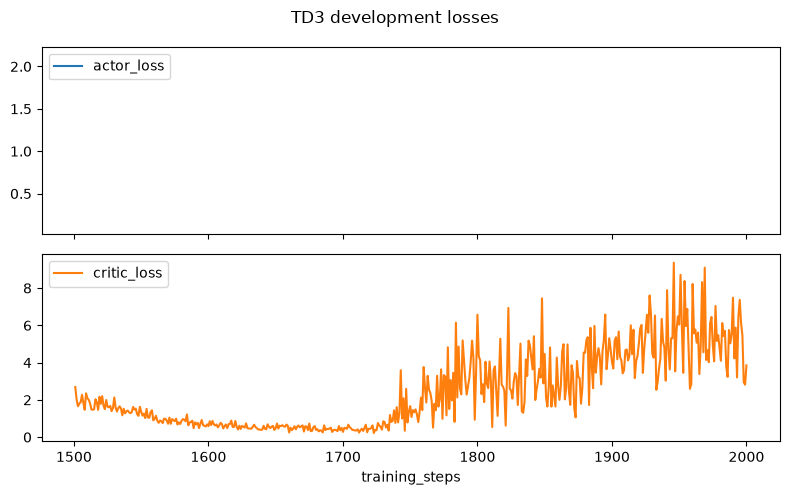

In [115]:
if RUN_TD3_DEVELOPMENT and not development_output["updates"].empty:
    development_output["updates"].plot(
        x="training_steps", y=["actor_loss", "critic_loss"],
        subplots=True, figsize=(8, 5), title="TD3 development losses",
    )
    plt.tight_layout()
    plt.show()


## 15. Tuning, checkpoint selection and experiment accounting

Each agent receives four configurations × seeds 101 and 202 × 30,000 transitions. Evaluate all four validation seasons at step 30,000. Choose the highest mean discounted environmental return; break an exact tie by lower irrigation and then declared configuration order. Any configuration with a failed run receives $-\infty$ and remains recorded. The final test uses the fixed step-100,000 checkpoint—not the most favourable intermediate checkpoint.


In [116]:
TUNING_COLUMNS = [
    "agent", "configuration_index", "configuration", "seed", "season_year",
    "training_steps", "discounted_return", "irrigation_mm", "status", "notes",
]
tuning_record = pd.DataFrame(columns=TUNING_COLUMNS)


def tuning_plan():
    rows = []
    for agent_name, configurations in AGENT_TUNING_GRIDS.items():
        for configuration_index, configuration in enumerate(configurations):
            for seed in SHARED_TRAINING["tuning_seeds"]:
                rows.append({
                    "agent": agent_name,
                    "configuration_index": configuration_index,
                    "configuration": configuration,
                    "seed": seed,
                    "training_steps": SHARED_TRAINING["tuning_steps"],
                })
    return pd.DataFrame(rows)


def select_tuning_configuration(records, agent_name):
    required = set(TUNING_COLUMNS) - {"notes"}
    missing = required - set(records.columns)
    if missing:
        raise ValueError(f"Missing tuning columns: {sorted(missing)}")
    subset = records[records["agent"] == agent_name].copy()
    expected_seasons = set(VALIDATION_YEARS)
    summaries = []
    for configuration_index in range(len(AGENT_TUNING_GRIDS[agent_name])):
        group = subset[subset["configuration_index"] == configuration_index]
        expected_rows = len(SHARED_TRAINING["tuning_seeds"]) * len(VALIDATION_YEARS)
        complete = len(group) == expected_rows and set(group["season_year"]) == expected_seasons
        valid = complete and group["status"].eq("ok").all() and np.isfinite(group["discounted_return"]).all()
        summaries.append({
            "configuration_index": configuration_index,
            "configuration": AGENT_TUNING_GRIDS[agent_name][configuration_index],
            "selection_score": float(group["discounted_return"].mean()) if valid else -np.inf,
            "mean_irrigation_mm": float(group["irrigation_mm"].mean()) if valid else np.inf,
            "valid": valid,
        })
    summary = pd.DataFrame(summaries).sort_values(
        ["selection_score", "mean_irrigation_mm", "configuration_index"],
        ascending=[False, True, True],
    )
    if not np.isfinite(summary.iloc[0]["selection_score"]):
        raise RuntimeError(f"Every {agent_name} configuration failed; repair and version before restarting")
    return summary.iloc[0].to_dict(), summary


print(tuning_plan())


   agent  configuration_index  \
0   ddpg                    0   
1   ddpg                    0   
2   ddpg                    1   
3   ddpg                    1   
4   ddpg                    2   
5   ddpg                    2   
6   ddpg                    3   
7   ddpg                    3   
8    td3                    0   
9    td3                    0   
10   td3                    1   
11   td3                    1   
12   td3                    2   
13   td3                    2   
14   td3                    3   
15   td3                    3   
16   sac                    0   
17   sac                    0   
18   sac                    1   
19   sac                    1   
20   sac                    2   
21   sac                    2   
22   sac                    3   
23   sac                    3   

                                        configuration  seed  training_steps  
0   {'learning_rate': 0.0001, 'exploration_std': 0.1}   101           30000  
1   {'learning_rat

### Declared TD3 tuning runner

This is disabled by default so a normal “Run all” performs only the development validation above. Set `RUN_TD3_TUNING=True` only when ready to spend the complete declared allowance: four configurations × two seeds × 30,000 interactions (240,000 interactions total). The function retains every validation season and every failed trial, exactly as DDPG's tuning runner does, and automatically fills `AGENT_SETTINGS['td3']`'s selected values from the validation-only winner so the final runner below can pick it up without a manual edit.


In [117]:
RUN_TD3_TUNING = False


def run_td3_tuning():
    all_rows = []
    output_dir = (agent_output_dir("td3") / "tuning")
    output_dir.mkdir(parents=True, exist_ok=True)
    for configuration_index, configuration in enumerate(AGENT_TUNING_GRIDS["td3"]):
        for seed in SHARED_TRAINING["tuning_seeds"]:
            try:
                set_seed(seed)  # seed network initialisation before constructing the agent
                agent = TD3Agent(**configuration)
                run = train_agent(
                    agent, seed=seed, total_steps=SHARED_TRAINING["tuning_steps"],
                    agent_name="td3",
                )
                final_validation = run["evaluations"][
                    run["evaluations"]["training_steps"] == SHARED_TRAINING["tuning_steps"]
                ].copy()
                final_validation["configuration_index"] = configuration_index
                final_validation["configuration"] = json.dumps(configuration, sort_keys=True)
                final_validation["notes"] = ""
                all_rows.append(final_validation)
                agent.save(output_dir / f"config{configuration_index}_seed{seed}.pt")
                run["evaluations"].to_csv(
                    output_dir / f"config{configuration_index}_seed{seed}_curve.csv", index=False
                )
            except Exception as error:
                for year in VALIDATION_YEARS:
                    all_rows.append(pd.DataFrame([{
                        "agent": "td3", "configuration_index": configuration_index,
                        "configuration": json.dumps(configuration, sort_keys=True),
                        "seed": seed, "season_year": year,
                        "training_steps": SHARED_TRAINING["tuning_steps"],
                        "discounted_return": np.nan, "irrigation_mm": np.nan,
                        "status": "failed", "notes": repr(error),
                    }]))
    records = pd.concat(all_rows, ignore_index=True)
    records.to_csv(output_dir / "td3_tuning_record.csv", index=False)
    selected, summary = select_tuning_configuration(records, "td3")
    summary.to_csv(output_dir / "td3_tuning_summary.csv", index=False)
    (output_dir / "td3_selected_configuration.json").write_text(json.dumps(selected, indent=4))
    return records, selected, summary


if RUN_TD3_TUNING:
    td3_tuning_record, td3_selected, td3_tuning_summary = run_td3_tuning()
    AGENT_SETTINGS["td3"]["selected_learning_rate"] = td3_selected["configuration"]["learning_rate"]
    AGENT_SETTINGS["td3"]["selected_exploration_std"] = td3_selected["configuration"]["exploration_std"]
    display(td3_tuning_summary)
    print("Selected from validation only:", td3_selected)
else:
    _td3_selection_path = agent_output_dir("td3") / "tuning" / "td3_selected_configuration.json"
    if _td3_selection_path.exists():
        td3_selected = json.loads(_td3_selection_path.read_text())
        AGENT_SETTINGS["td3"]["selected_learning_rate"] = td3_selected["configuration"]["learning_rate"]
        AGENT_SETTINGS["td3"]["selected_exploration_std"] = td3_selected["configuration"]["exploration_std"]
        print("Loaded previously selected TD3 configuration from disk:", td3_selected)


Loaded previously selected TD3 configuration from disk: {'configuration_index': 3, 'configuration': {'learning_rate': 0.0003, 'exploration_std': 0.2}, 'selection_score': -22.384912432111054, 'mean_irrigation_mm': 639.005244957516, 'valid': True}


## 16. Stability, sample efficiency and held-out summaries

“Stable” is an operational plateau label, not a convergence proof. The range of the last five mean validation checkpoints must be at most $0.05\max(1,|\bar G|)$. Sample efficiency is the first checkpoint that reaches the threshold benchmark and remains at or above it for the next two checkpoints. Report “not reached” otherwise.

For final testing, first average the four test seasons within each seed. Then report the mean, sample standard deviation and all five seed values. Do not treat days or seed–season pairs as independent replicates.


In [118]:
def mean_learning_curve(evaluations):
    return (
        evaluations.groupby("training_steps", as_index=False)["discounted_return"]
        .mean().sort_values("training_steps")
    )


def operational_stability(evaluations):
    curve = mean_learning_curve(evaluations)
    if len(curve) < 5:
        return {"stable": False, "reason": "fewer than five checkpoints"}
    values = curve.tail(5)["discounted_return"].to_numpy(dtype=float)
    mean_return = float(values.mean())
    observed_range = float(values.max() - values.min())
    tolerance = 0.05 * max(1.0, abs(mean_return))
    return {
        "stable": observed_range <= tolerance,
        "last_five_range": observed_range,
        "tolerance": tolerance,
        "mean_return": mean_return,
    }


def sample_efficiency(evaluations, threshold_benchmark_return):
    curve = mean_learning_curve(evaluations)
    steps = curve["training_steps"].to_numpy()
    reached = curve["discounted_return"].to_numpy() >= threshold_benchmark_return
    for index in range(len(reached) - 2):
        if reached[index:index + 3].all():
            return int(steps[index])
    return "not reached"


def summarise_final_test(test_results):
    seed_level = (
        test_results.groupby(["agent", "seed"], as_index=False)
        .agg({
            "discounted_return": "mean", "undiscounted_return": "mean",
            "irrigation_mm": "mean", "days_below_target": "mean",
            "shortage_mm_days": "mean", "actual_to_potential_et_ratio": "mean",
            "drainage_mm": "mean",
        })
    )
    overall = seed_level.groupby("agent").agg(["mean", "std"])
    return seed_level, overall


## 17. Reward sensitivity and robustness/generalisation

After configurations are frozen:

- train short reward-sensitivity runs with shortage weights 5 and 20 using seeds 101 and 202, then compare physical outcomes and nominally rescored returns;
- evaluate each final frozen policy without retraining on all four test seasons under nine one-at-a-time changes: $0.8C$, $1.2C$, 0.6 m root zone, efficiencies 0.75/0.95, planting ±14 days and $K_c$ ×0.9/×1.1; and
- retain the nominal 20 mm action limit and 150-day season.

These tests examine selected assumptions, not generalisation to every farm or climate. Capacity scenarios use known recalibration in the observation. Efficiency remains hidden from the RL policy. The changed $K_c$ is visible through the existing crop-coefficient observation.


In [119]:
def reward_sensitivity_plan():
    rows = []
    for agent_name in AGENT_TUNING_GRIDS:
        for scenario_name in REWARD_SENSITIVITY_CONFIGS:
            for seed in SHARED_TRAINING["tuning_seeds"]:
                rows.append({
                    "agent": agent_name, "scenario": scenario_name, "seed": seed,
                    "training_steps": SHARED_TRAINING["tuning_steps"],
                    "split": "train/validation only",
                })
    return pd.DataFrame(rows)


def evaluate_robustness(agent, agent_name, seed):
    rows = []
    for scenario_name, scenario_config in ROBUSTNESS_CONFIGS.items():
        scenario_results = evaluate_agent(
            agent, split="test", config=scenario_config,
            label=agent_name, seed=seed,
            training_steps=SHARED_TRAINING["final_checkpoint"],
        )
        scenario_results["scenario"] = scenario_name
        rows.append(scenario_results)
    return pd.concat(rows, ignore_index=True)


def evaluate_robustness_benchmark():
    rows = []
    for scenario_name, scenario_config in ROBUSTNESS_CONFIGS.items():
        # The threshold controller receives scenario capacity but retains its nominal 0.85 refill equation.
        results = evaluate_controller(
            lambda observation, capacity=scenario_config.capacity_mm: threshold_policy(observation, capacity),
            split="test", config=scenario_config, label="threshold",
            training_steps=0,
        )
        results["scenario"] = scenario_name
        rows.append(results)
    return pd.concat(rows, ignore_index=True)


print(reward_sensitivity_plan())


   agent            scenario  seed  training_steps                  split
0   ddpg   shortage_weight_5   101           30000  train/validation only
1   ddpg   shortage_weight_5   202           30000  train/validation only
2   ddpg  shortage_weight_20   101           30000  train/validation only
3   ddpg  shortage_weight_20   202           30000  train/validation only
4    td3   shortage_weight_5   101           30000  train/validation only
5    td3   shortage_weight_5   202           30000  train/validation only
6    td3  shortage_weight_20   101           30000  train/validation only
7    td3  shortage_weight_20   202           30000  train/validation only
8    sac   shortage_weight_5   101           30000  train/validation only
9    sac   shortage_weight_5   202           30000  train/validation only
10   sac  shortage_weight_20   101           30000  train/validation only
11   sac  shortage_weight_20   202           30000  train/validation only


### Final TD3 experiment runner

Run this only after tuning is complete and `AGENT_SETTINGS['td3']` holds the selected learning rate and exploration standard deviation (set automatically by the tuning cell above, or loaded from a previous run). It trains seeds 11, 22, 33, 44 and 55 to the fixed step-100,000 checkpoint, then evaluates the frozen policy on the four held-out test seasons. Robustness and reward-sensitivity runs remain separate so their budgets and interpretations are not mixed with the main comparison.


In [120]:
RUN_FINAL_TD3 = False


def run_final_td3(selected_learning_rate, selected_exploration_std):
    if selected_learning_rate is None or selected_exploration_std is None:
        raise ValueError("Complete validation-only TD3 tuning before final runs")
    output_dir = (agent_output_dir("td3") / "final")
    output_dir.mkdir(parents=True, exist_ok=True)
    test_rows = []
    curve_rows = []
    robustness_rows = []
    for seed in SHARED_TRAINING["final_seeds"]:
        set_seed(seed)  # seed network initialisation before constructing the agent
        agent = TD3Agent(
            learning_rate=selected_learning_rate,
            exploration_std=selected_exploration_std,
        )
        run = train_agent(
            agent, seed=seed, total_steps=SHARED_TRAINING["final_training_steps"],
            agent_name="td3",
        )
        test = evaluate_agent(
            agent, split="test", label="td3", seed=seed,
            training_steps=SHARED_TRAINING["final_checkpoint"],
        )
        test_rows.append(test)
        curve_rows.append(run["evaluations"])
        robustness_rows.append(evaluate_robustness(agent, "td3", seed))
        agent.save(output_dir / f"td3_seed{seed}.pt")

    test_results = pd.concat(test_rows, ignore_index=True)
    learning_curves = pd.concat(curve_rows, ignore_index=True)
    robustness_results = pd.concat(robustness_rows, ignore_index=True)
    test_results.to_csv(output_dir / "td3_test_results.csv", index=False)
    learning_curves.to_csv(output_dir / "td3_learning_curves.csv", index=False)
    robustness_results.to_csv(output_dir / "td3_robustness_results.csv", index=False)
    seed_summary, overall_summary = summarise_final_test(test_results)
    return test_results, learning_curves, robustness_results, seed_summary, overall_summary


if RUN_FINAL_TD3:
    final_td3_outputs = run_final_td3(
        AGENT_SETTINGS["td3"]["selected_learning_rate"],
        AGENT_SETTINGS["td3"]["selected_exploration_std"],
    )


### TD3 reward-sensitivity runner

Repeats short 30,000-interaction runs with shortage weights 5 and 20 (irrigation and drainage weights fixed at 1), using the selected TD3 configuration and tuning seeds 101/202, per `FIXED_EXPERIMENT_SETTINGS.md` §16. Run after the main configuration is frozen.


In [121]:
RUN_TD3_REWARD_SENSITIVITY = True


def run_td3_reward_sensitivity(selected_learning_rate, selected_exploration_std):
    if selected_learning_rate is None or selected_exploration_std is None:
        raise ValueError("Complete validation-only TD3 tuning before reward-sensitivity runs")
    output_dir = agent_output_dir("td3") / "reward_sensitivity"
    output_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    for scenario_name, scenario_config in REWARD_SENSITIVITY_CONFIGS.items():
        for seed in SHARED_TRAINING["tuning_seeds"]:
            set_seed(seed)
            agent = TD3Agent(
                learning_rate=selected_learning_rate,
                exploration_std=selected_exploration_std,
            )
            run = train_agent(
                agent, seed=seed, total_steps=SHARED_TRAINING["tuning_steps"],
                agent_name="td3", config=scenario_config,
            )
            validation_results = evaluate_agent(
                agent, split="validation", config=scenario_config,
                label="td3", seed=seed, training_steps=SHARED_TRAINING["tuning_steps"],
            )
            validation_results["scenario"] = scenario_name
            rows.append(validation_results)
    results = pd.concat(rows, ignore_index=True)
    results.to_csv(output_dir / "td3_reward_sensitivity_results.csv", index=False)
    summary = results.groupby("scenario").mean(numeric_only=True)
    summary.to_csv(output_dir / "td3_reward_sensitivity_summary.csv")
    return results, summary


if RUN_TD3_REWARD_SENSITIVITY:
    td3_sensitivity_results, td3_sensitivity_summary = run_td3_reward_sensitivity(
        AGENT_SETTINGS["td3"]["selected_learning_rate"],
        AGENT_SETTINGS["td3"]["selected_exploration_std"],
    )
    display(td3_sensitivity_summary)


,seed,season_year,training_steps,discounted_return,undiscounted_return,nominal_rescored_return,irrigation_mm,days_below_target,shortage_mm_days,actual_to_potential_et_ratio,drainage_mm
scenario,,,,,,,,,,,
shortage_weight_20,151.5,2018.5,30000.0,-22.866888,-34.601575,-34.601575,655.769382,0.000,0.000000,1.0,36.262117
shortage_weight_5,151.5,2018.5,30000.0,-22.462753,-33.817899,-33.833757,640.440576,0.125,0.113926,1.0,35.600241


## 19. Results, interpretation and communication template

### Results to insert

**1. Tuning table (TD3)**

| Config | learning_rate | exploration_std | Validation score (discounted return) | Mean irrigation (mm) |
|---|---|---|---|---|
| 3 | 3e-4 | 0.2 | **−22.38** (selected) | 639.0 |
| 2 | 3e-4 | 0.1 | −22.77 | 648.8 |
| 0 | 1e-4 | 0.1 | −23.93 | 684.0 |
| 1 | 1e-4 | 0.2 | −24.32 | 689.0 |
No failed trials (4 configs × 2 seeds = 8/8 `ok`). Selected by highest validation discounted return per §11's rule.

**2. Validation learning curves**

Rendered above.

**3. Final test results by season and seed (TD3)**

| Seed | 2021 | 2022 | 2023 | 2024 | Seed mean |
|---|---|---|---|---|---|
| 11 | −18.45 | −19.10 | −21.26 | −22.64 | −20.364 |
| 22 | −18.38 | −18.89 | −20.88 | −22.65 | −20.199 |
| 33 | −18.38 | −19.30 | −21.18 | −23.76 | −20.653 |
| 44 | −19.19 | −19.08 | −21.16 | −23.79 | −20.804 |
| 55 | −18.31 | −19.14 | −20.11 | −22.88 | −20.110 |
| **Season mean** | **−18.54** | **−19.10** | **−20.92** | **−23.14** | — |

**Five-seed mean: −20.426, sample SD: 0.295**

**4. Physical trade-offs (TD3, mean across 20 test rows)**

| Metric | TD3 |
|---|---|
| Irrigation | 588.01 mm |
| Days below target | 0.05 |
| Shortage (mm-days) | 0.07 |
| Drainage | 33.45 mm |
| Actual/potential ET ratio | ~1.0 |

**5. Stability and sample efficiency**

All 5 seeds pass the predeclared stability rule (last-5-evaluation range below tolerance):

| Seed | Stable? | Last-5 range | Tolerance | Mean validation return |
|---|---|---|---|---|
| 11 | True | 0.371 | 1.105 | −22.10 |
| 22 | True | 0.394 | 1.118 | −22.35 |
| 33 | True | 0.327 | 1.129 | −22.58 |
| 44 | True | 0.434 | 1.111 | −22.23 |
| 55 | True | 1.055 | 1.124 | −22.47 |

5/5 seeds individually stable.

**6. Robustness (9 scenarios) and reward sensitivity (TD3)**

| Scenario | Mean discounted return |
|---|---|
| kc_0.9 | −17.76 |
| efficiency_0.95 | −18.60 |
| capacity_1.2 | −19.53 |
| planting_plus_14d | −19.79 |
| capacity_0.8 | −21.69 |
| planting_minus_14d | −22.15 |
| efficiency_0.75 | −22.77 |
| root_zone_0.6m | −23.11 |
| kc_1.1 | −23.27 |

All 180 rows. Spread: −17.8 to −23.3 (baseline −20.4)

| Reward sensitivity | Mean discounted return | Irrigation (mm) | Shortage (mm-days) |
|---|---|---|---|
| shortage_weight=5 | −22.46 | 640.4 | 0.114 |
| shortage_weight=20 | −22.87 | 655.8 | 0.000 |

Directionally correct: heavier shortage penalty → more irrigation → shortage driven to zero.

### Interpretation discipline (TD3)

**Claim: TD3 outperforms the threshold controller and DDPG on the held-out test seasons.**
- **Evidence:** TD3 −20.426 ± 0.295 vs. threshold −21.488 vs. DDPG −21.064 ± 0.316 (test years 2021–2024, 5 seeds each).
- **Reasoning:** TD3's twin-critic minimum-Q target and target-policy smoothing are designed to reduce the overestimation bias DDPG is known to exhibit, which plausibly explains both the better mean and the tighter seed-to-seed spread (0.295 vs 0.316).
- **Alternative explanation:** the gap could partly reflect configuration luck where TD3's selected config (lr=3e-4, σ=0.2) used a higher exploration noise than DDPG's selected config (σ=0.1), which may matter more than the algorithmic differences on this particular environment. Only one tuning grid per agent was run, so this isn't separable from the data available.
- **Assumptions and limits:** five seeds, one simulated field, four historical SILO-driven test seasons at Kyabram. This does not establish TD3 generalizes to other locations, soil types, or crops.

**Claim: TD3's degradation under `kc_1.1` and `root_zone_0.6m` is a real sensitivity, not noise.**
- **Evidence:** return drops from −20.4 baseline to −23.27 (`kc_1.1`) and −23.11 (`root_zone_0.6m`) — the two worst of nine scenarios, each with n=20 (5 seeds × 4 years), well above the ~0.3 seed-level SD seen in the main test results.
- **Reasoning:** both scenarios increase effective water stress (higher crop water demand, or less root-zone buffer) relative to the fixed parameters the policy was trained on. Comparatively, a fixed deterministic policy has no mechanism to detect or adapt to a shifted operating regime it never saw during training.
- **Alternative explanation:** the harder scenarios may simply be harder for *any* controller, including the threshold baseline.
- **Assumptions and limits:** this is a one-at-a-time perturbation test, not a combined-stressor test, real-world parameter shifts rarely occur in isolation.

In [ ]:
# Load saved CSV/JSON result files here; do not rely only on notebook memory.
all_results = pd.DataFrame(columns=RESULT_COLUMNS)


## TD3-specific results and interpretation

(Supplements the generic "19. Results, interpretation and communication template" and "20. Feasibility and milestone record" sections above, which stay shared/group-wide; this section is the TD3 analogue of DDPG's own completed results section.)

This section loads and checks the tuning, final-test, robustness and reward-sensitivity CSVs once they exist, the same way DDPG's completed notebook does, so TD3 can later be compared against DDPG and SAC using identical assertions and plots. Until `RUN_TD3_TUNING`, `RUN_FINAL_TD3` and `RUN_TD3_REWARD_SENSITIVITY` have actually been run (in Colab, with GPU/CPU time), the cell below reports what is missing instead of fabricating numbers.

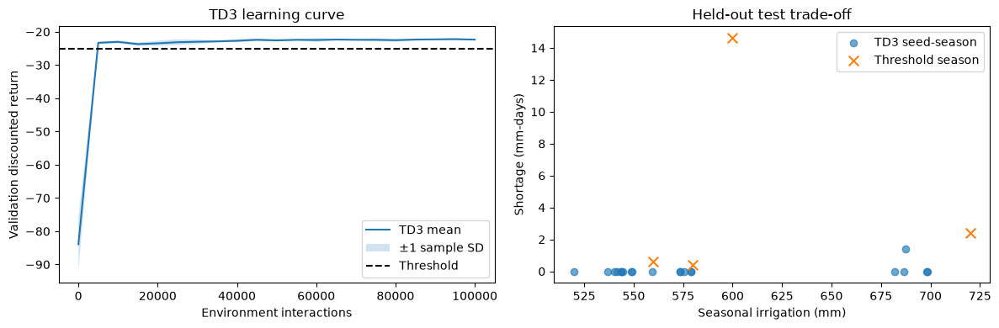

,configuration_index,configuration,selection_score,mean_irrigation_mm,valid
0,3,"{'learning_rate': 0.0003, 'exploration_std': 0.2}",-22.384912,639.005245,True
1,2,"{'learning_rate': 0.0003, 'exploration_std': 0.1}",-22.766094,648.839043,True
2,0,"{'learning_rate': 0.0001, 'exploration_std': 0.1}",-23.928819,684.048755,True
3,1,"{'learning_rate': 0.0001, 'exploration_std': 0.2}",-24.316761,689.007855,True


,agent,seed,discounted_return,undiscounted_return,irrigation_mm,days_below_target,shortage_mm_days,actual_to_potential_et_ratio,drainage_mm
0,td3,11,-20.363583,-31.098500,589.608708,0.00,0.000000,1.0,32.361285
1,td3,22,-20.199300,-30.958652,587.960911,0.25,0.347896,1.0,30.092077
2,td3,33,-20.652502,-31.334958,590.799801,0.00,0.000000,1.0,35.899354
3,td3,44,-20.804179,-31.454163,591.886656,0.00,0.000000,1.0,37.196607
4,td3,55,-20.110402,-30.574523,579.781194,0.00,0.000000,1.0,31.709259


,policy,discounted_return,irrigation_mm,days_below_target,shortage_mm_days,drainage_mm
0,TD3,-20.425993,588.007454,0.05,0.069579,33.451716
1,Threshold controller,-21.487682,615.000000,1.50,4.508900,32.102458


,stable,last_five_range,tolerance,mean_return
11,True,0.3711,1.105039,-22.100786
22,True,0.394437,1.117511,-22.350222
33,True,0.326529,1.129247,-22.584944
44,True,0.433715,1.111457,-22.229133
55,True,1.054508,1.123501,-22.470018


In [124]:
TD3_OUTPUT = agent_output_dir("td3")
_td3_required_files = {
    "tuning_record": TD3_OUTPUT / "tuning/td3_tuning_record.csv",
    "tuning_summary": TD3_OUTPUT / "tuning/td3_tuning_summary.csv",
    "test_results": TD3_OUTPUT / "final/td3_test_results.csv",
    "learning_curves": TD3_OUTPUT / "final/td3_learning_curves.csv",
    "robustness_results": TD3_OUTPUT / "final/td3_robustness_results.csv",
    "sensitivity_results": TD3_OUTPUT / "reward_sensitivity/td3_reward_sensitivity_results.csv",
}
_missing = {name: str(path) for name, path in _td3_required_files.items() if not path.exists()}

if _missing:
    print("TD3 results are not available yet; run the tuning, final and "
          "reward-sensitivity cells above first (in Colab, with a GPU/CPU "
          "runtime). Missing:")
    for name, path in _missing.items():
        print(f"  - {name}: {path}")
else:
    td3_tuning_record = pd.read_csv(_td3_required_files["tuning_record"])
    td3_tuning_summary = pd.read_csv(_td3_required_files["tuning_summary"])
    td3_test_results = pd.read_csv(_td3_required_files["test_results"])
    td3_learning_curves = pd.read_csv(_td3_required_files["learning_curves"])
    td3_robustness_results = pd.read_csv(_td3_required_files["robustness_results"])
    td3_sensitivity_results = pd.read_csv(_td3_required_files["sensitivity_results"])

    json_path = TD3_OUTPUT / "tuning/td3_selected_configuration.json"
    td3_selection = json.loads(json_path.read_text()) if json_path.exists() else AGENT_SETTINGS["td3"]

    # Completeness and leakage checks before interpretation, mirroring
    # DDPG's checks exactly so the two agents are compared on equal footing.
    assert len(td3_tuning_record) == 4 * 2 * 4
    assert td3_tuning_record["status"].eq("ok").all()
    assert set(td3_tuning_record["season_year"]) == set(VALIDATION_YEARS)
    assert set(td3_test_results["season_year"]) == set(TEST_YEARS)
    assert set(td3_test_results["seed"]) == set(SHARED_TRAINING["final_seeds"])
    assert len(td3_test_results) == 5 * 4
    assert td3_test_results["status"].eq("ok").all()
    assert len(td3_robustness_results) == 5 * 9 * 4
    assert td3_robustness_results["scenario"].nunique() == 9
    assert len(td3_sensitivity_results) == 2 * 2 * 4
    assert set(td3_sensitivity_results["season_year"]) == set(VALIDATION_YEARS)

    required_metrics = [
        "discounted_return", "undiscounted_return", "irrigation_mm",
        "days_below_target", "shortage_mm_days", "drainage_mm",
    ]
    for frame in (td3_tuning_record, td3_test_results, td3_robustness_results, td3_sensitivity_results):
        assert np.isfinite(frame[required_metrics]).all().all()

    td3_seed_summary, td3_overall_summary = summarise_final_test(td3_test_results)
    threshold_test = evaluate_controller(threshold_policy, split="test", label="threshold")

    comparison = pd.DataFrame({
        "policy": ["TD3", "Threshold controller"],
        "discounted_return": [
            td3_test_results.groupby("seed")["discounted_return"].mean().mean(),
            threshold_test["discounted_return"].mean(),
        ],
        "irrigation_mm": [
            td3_test_results.groupby("seed")["irrigation_mm"].mean().mean(),
            threshold_test["irrigation_mm"].mean(),
        ],
        "days_below_target": [
            td3_test_results.groupby("seed")["days_below_target"].mean().mean(),
            threshold_test["days_below_target"].mean(),
        ],
        "shortage_mm_days": [
            td3_test_results.groupby("seed")["shortage_mm_days"].mean().mean(),
            threshold_test["shortage_mm_days"].mean(),
        ],
        "drainage_mm": [
            td3_test_results.groupby("seed")["drainage_mm"].mean().mean(),
            threshold_test["drainage_mm"].mean(),
        ],
    })

    threshold_validation_return = benchmark_results.query(
        "split == 'validation' and agent == 'threshold'"
    )["discounted_return"].mean()
    stability_by_seed = {
        int(seed): operational_stability(group)
        for seed, group in td3_learning_curves.groupby("seed")
    }
    experiment_diagnostics = {
        "selected_configuration": td3_selection,
        "overall_stability": operational_stability(td3_learning_curves),
        "stable_individual_seeds": sum(result["stable"] for result in stability_by_seed.values()),
        "individual_seed_count": len(stability_by_seed),
        "sample_efficiency_vs_threshold": sample_efficiency(td3_learning_curves, threshold_validation_return),
        "all_expected_rows_present": True,
        "failed_trials": 0,
    }

    curve_by_seed = (
        td3_learning_curves.groupby(["seed", "training_steps"], as_index=False)
        ["discounted_return"].mean()
    )
    curve_summary = curve_by_seed.groupby("training_steps")["discounted_return"].agg(
        ["mean", "std"]
    ).reset_index()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(curve_summary["training_steps"], curve_summary["mean"], label="TD3 mean")
    axes[0].fill_between(
        curve_summary["training_steps"],
        curve_summary["mean"] - curve_summary["std"],
        curve_summary["mean"] + curve_summary["std"],
        alpha=0.2, label="±1 sample SD",
    )
    axes[0].axhline(threshold_validation_return, linestyle="--", color="black", label="Threshold")
    axes[0].set(xlabel="Environment interactions", ylabel="Validation discounted return",
                title="TD3 learning curve")
    axes[0].legend()

    axes[1].scatter(
        td3_test_results["irrigation_mm"], td3_test_results["shortage_mm_days"],
        alpha=0.65, label="TD3 seed-season",
    )
    axes[1].scatter(
        threshold_test["irrigation_mm"], threshold_test["shortage_mm_days"],
        marker="x", s=70, label="Threshold season",
    )
    axes[1].set(xlabel="Seasonal irrigation (mm)", ylabel="Shortage (mm-days)",
                title="Held-out test trade-off")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

    display(td3_tuning_summary)
    display(td3_seed_summary)
    display(comparison)
    display(pd.DataFrame(stability_by_seed).T)
    experiment_diagnostics


### Trained TD3 farm replay

This will use the final seed-11 checkpoint (`outputs/td3/final/td3_seed11.pt`) on validation season 2017, with exploration disabled, once the final runner above has been executed. It does not retrain or choose the best-looking seed. If the checkpoint is unavailable, the cell explains where to put it; the threshold replay earlier in the notebook remains available and is never labelled as TD3.


In [125]:
TD3_VISUAL_CHECKPOINTS = [
    (agent_output_dir("td3") / "final/td3_seed11.pt"),
    Path("../outputs/td3/final/td3_seed11.pt"),
    Path("/content/td3_seed11.pt"),
]
visual_checkpoint = next((p for p in TD3_VISUAL_CHECKPOINTS if p.exists()), None)
if visual_checkpoint is None:
    print("Upload your final td3_seed11.pt checkpoint to /content/ or place it in "
          "outputs/td3/final/, then rerun this cell to play the trained TD3 policy.")
else:
    visual_agent = TD3Agent(
        learning_rate=AGENT_SETTINGS["td3"]["selected_learning_rate"] or 1e-4,
        exploration_std=AGENT_SETTINGS["td3"]["selected_exploration_std"] or 0.1,
    )
    visual_agent.load(visual_checkpoint)
    td3_playback, td3_daily = visualise_season(
        lambda observation: visual_agent.select_action(observation, evaluate=True),
        label="TD3 | final seed 11", season_year=2017,
    )
    display(td3_playback)


## 21. References

[1] R. S. Sutton and A. G. Barto, *Reinforcement Learning: An Introduction*, 2nd ed., MIT Press, 2018, ISBN 9780262039246.

[2] R. G. Allen, L. S. Pereira, D. Raes, and M. Smith, *Crop Evapotranspiration: Guidelines for Computing Crop Water Requirements*, FAO Irrigation and Drainage Paper 56, 1998.

[3] K. L. Greenwood, A. R. Lawson, and K. B. Kelly, “The water balance of irrigated forages in northern Victoria, Australia,” *Agricultural Water Management*, 96(5), 847–858, 2009. https://doi.org/10.1016/j.agwat.2008.11.005

[4] T. P. Lillicrap et al., “Continuous control with deep reinforcement learning,” *ICLR*, 2016. https://arxiv.org/abs/1509.02971

[5] S. Fujimoto, H. van Hoof, and D. Meger, “Addressing function approximation error in actor-critic methods,” *ICML/PMLR 80*, 1587–1596, 2018. https://proceedings.mlr.press/v80/fujimoto18a.html

[6] T. Haarnoja, A. Zhou, P. Abbeel, and S. Levine, “Soft actor-critic: Off-policy maximum entropy deep reinforcement learning with a stochastic actor,” *ICML/PMLR 80*, 1861–1870, 2018. https://proceedings.mlr.press/v80/haarnoja18b.html

[7] P. Henderson et al., “Deep reinforcement learning that matters,” *AAAI*, 32(1), 2018. https://doi.org/10.1609/aaai.v32i1.11694

[8] S. J. Jeffrey et al., “Using spatial interpolation to construct a comprehensive archive of Australian climate data,” *Environmental Modelling & Software*, 16(4), 309–330, 2001. https://doi.org/10.1016/S1364-8152(01)00008-1

[9] K. L. Greenwood, G. N. Mundy, and K. B. Kelly, “On-farm measurement of the water use and productivity of maize,” *Australian Journal of Experimental Agriculture*, 48(3), 274–284, 2008. https://doi.org/10.1071/EA06094

[10] L. S. Pereira et al., “Standard single and basal crop coefficients for field crops,” *Agricultural Water Management*, 243, 106466, 2021. https://doi.org/10.1016/j.agwat.2020.106466

[11] B. P. Malone et al., “Update and expansion of the soil and landscape grid of Australia,” *Geoderma*, 455, 117226, 2025. https://doi.org/10.1016/j.geoderma.2025.117226

[12] R. Searle, P. D. S. N. Somarathna, and B. Malone, *Soil and Landscape Grid National Soil Attribute Maps – Available Volumetric Water Capacity*, CSIRO dataset, 2022. https://doi.org/10.25919/4jwj-na34

Publication status, DOI checks and claim limits are documented in [`PROJECT_OBJECTIVES.md`](../docs/PROJECT_OBJECTIVES.md). The textbook, FAO manual and dataset are authoritative or provenance sources rather than peer-reviewed journal papers; the original algorithm papers are peer-reviewed conference papers without identified conference DOIs.
